In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('loan_approval_data.csv')

In [3]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    str    
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    str    
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    str    
 15  Property_Area       950 non-null    str    
 16  Education_Level   

In [5]:
df.isnull().sum()
df.describe()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


### Handling Missing Values

In [6]:
categorical_cols = df.select_dtypes(include=["str"]).columns
numerical_cols = df.select_dtypes(include=["number"]).columns

In [7]:
categorical_cols.size + numerical_cols.size

20

In [8]:
numerical_cols

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='str')

In [9]:
from sklearn.impute import SimpleImputer

numerical_imputer = SimpleImputer(strategy="mean")
df[numerical_cols] = numerical_imputer.fit_transform(df[numerical_cols])

In [10]:
categorical_imputer = SimpleImputer(strategy="most_frequent")
df[categorical_cols] = categorical_imputer.fit_transform(df[categorical_cols])

In [11]:
df.isnull().sum() # Handled all the missing values successfully !

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

### Exploratory Data Analysis

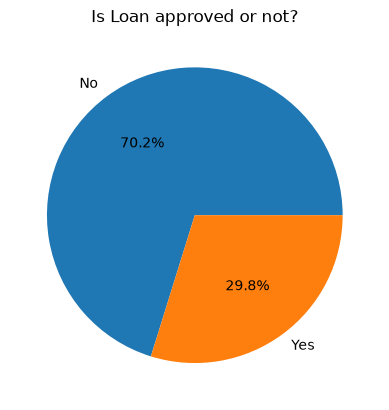

In [12]:
# To check how balanced our classed are.
classes_count = df['Loan_Approved'].value_counts()
plt.pie(classes_count, labels=["No", "Yes"], autopct="%1.1f%%")
plt.title("Is Loan approved or not?")
plt.show()

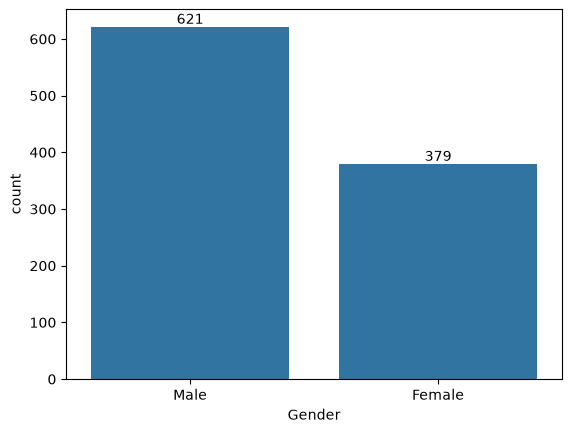

In [13]:
# Analyze Categories
gender_count = df["Gender"].value_counts()
ax = sns.barplot(gender_count)
ax.bar_label(ax.containers[0])
plt.show()

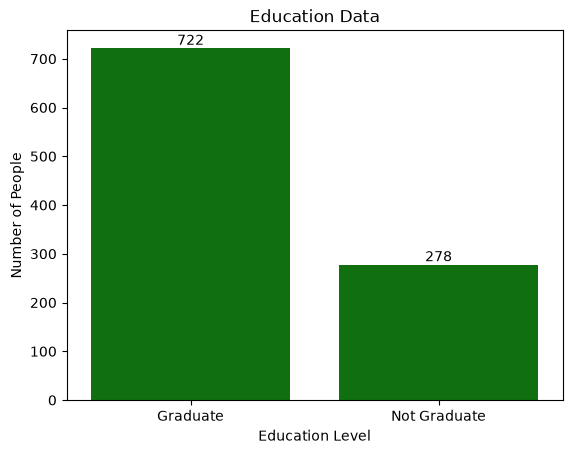

In [14]:
education_count = df["Education_Level"].value_counts()
ax = sns.barplot(education_count, color="green")
ax.bar_label(ax.containers[0])
ax.set_title("Education Data")
ax.set_xlabel("Education Level")
ax.set_ylabel("Number of People")
plt.show()

In [15]:
print(categorical_cols)

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='str')


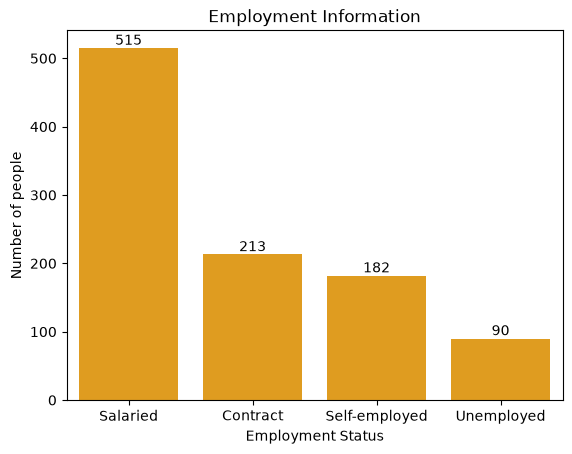

In [16]:
emp_status_counts = df["Employment_Status"].value_counts()
ax = sns.barplot(emp_status_counts, color='orange')
ax.bar_label(ax.containers[0])
ax.set_title("Employment Information")
ax.set_xlabel("Employment Status")
ax.set_ylabel("Number of people")
plt.show()

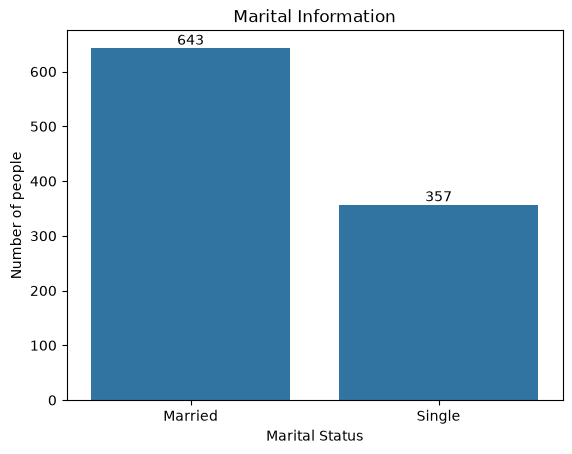

In [17]:
marital_status_count = df['Marital_Status'].value_counts()
ax = sns.barplot(marital_status_count)
ax.bar_label(ax.containers[0])
ax.set_title("Marital Information")
ax.set_xlabel("Marital Status")
ax.set_ylabel("Number of people")
plt.show()

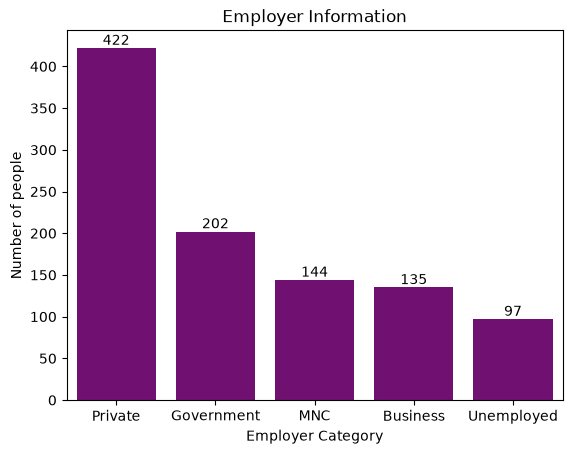

In [18]:
employer_category_count = df['Employer_Category'].value_counts()
ax = sns.barplot(employer_category_count, color='purple')
ax.bar_label(ax.containers[0])
ax.set_title("Employer Information")
ax.set_xlabel("Employer Category")
ax.set_ylabel("Number of people")
plt.show()

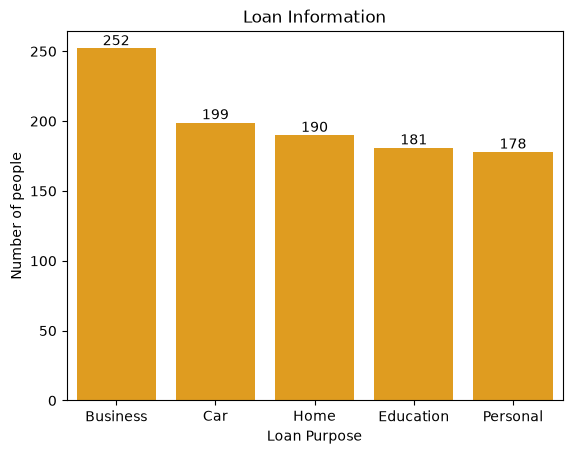

In [19]:
loan_purpose_count = df['Loan_Purpose'].value_counts()
ax = sns.barplot(loan_purpose_count, color='orange')
ax.bar_label(ax.containers[0])
ax.set_title("Loan Information")
ax.set_xlabel("Loan Purpose")
ax.set_ylabel("Number of people")
plt.show()

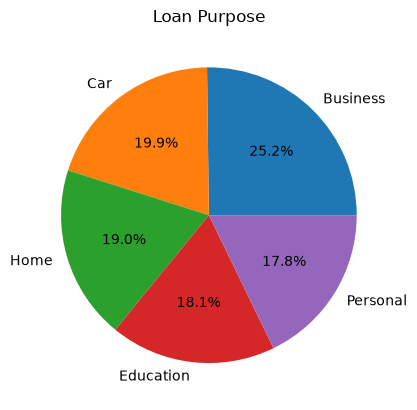

In [20]:
# To check how balanced our classed are.
loan_purpose_count = df['Loan_Purpose'].value_counts()
plt.pie(loan_purpose_count, labels=["Business", "Car", "Home", "Education", "Personal"], autopct="%1.1f%%")
plt.title("Loan Purpose")
plt.show()

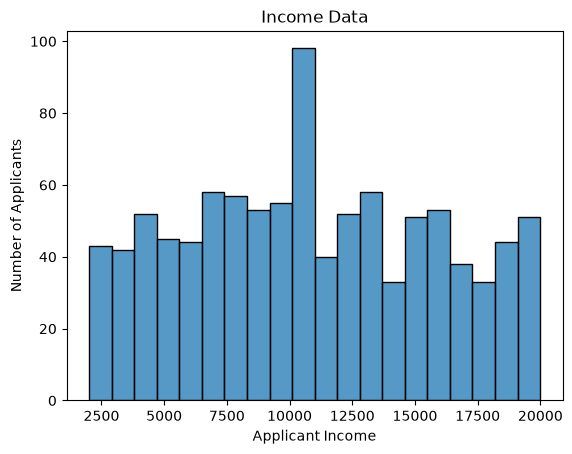

In [21]:
# Analyzing Income
ax = sns.histplot(
    data=df,
    x = 'Applicant_Income',
    bins=20
)
ax.set_title("Income Data")
ax.set_xlabel("Applicant Income")
ax.set_ylabel("Number of Applicants")
plt.show()

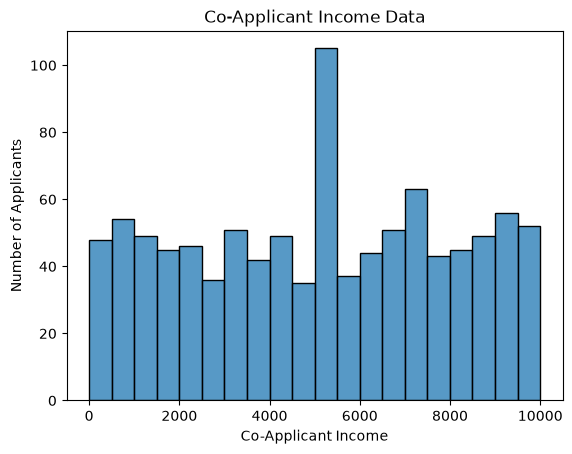

In [22]:
ax = sns.histplot(
    data=df,
    x = 'Coapplicant_Income',
    bins=20
)
ax.set_title("Co-Applicant Income Data")
ax.set_xlabel("Co-Applicant Income")
ax.set_ylabel("Number of Applicants")
plt.show()

In [23]:
# Outlier Detection - Box Plots

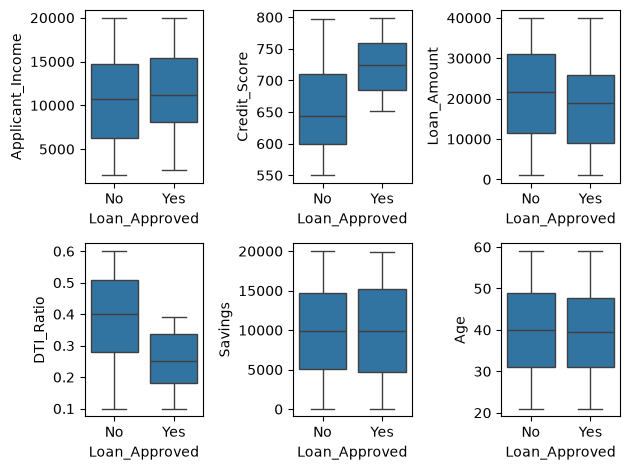

In [24]:
fig, axes = plt.subplots(2, 3)

sns.boxplot(ax=axes[0,0], data=df, x='Loan_Approved', y='Applicant_Income')
sns.boxplot(ax=axes[0,1], data=df, x='Loan_Approved', y='Credit_Score')
sns.boxplot(ax=axes[0,2], data=df, x='Loan_Approved', y='Loan_Amount')

sns.boxplot(ax=axes[1,0], data=df, x='Loan_Approved', y='DTI_Ratio')
sns.boxplot(ax=axes[1,1], data=df, x='Loan_Approved', y='Savings')
sns.boxplot(ax=axes[1,2], data=df, x='Loan_Approved', y='Age')

plt.tight_layout()

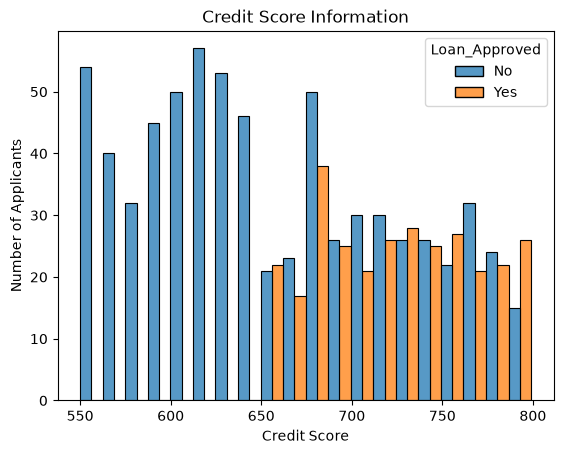

In [25]:
# Credit Score with Loan Approved
ax = sns.histplot(
    data = df,
    x = "Credit_Score", 
    hue = "Loan_Approved",
    bins=20,
    multiple = "dodge"
)

ax.set_title("Credit Score Information")
ax.set_xlabel("Credit Score")
ax.set_ylabel("Number of Applicants")
plt.show()

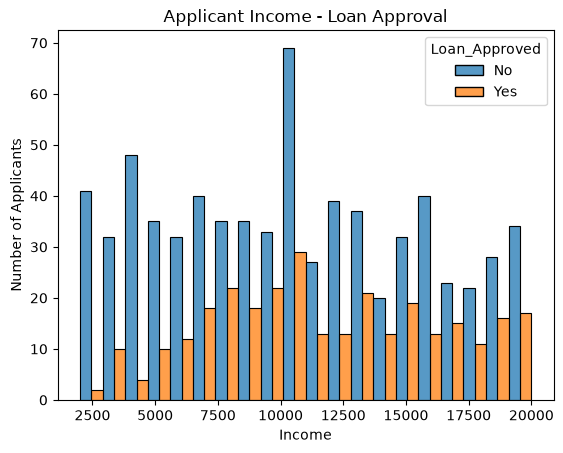

In [26]:
# Applicant Income with Loan Approved
ax = sns.histplot(
    data = df,
    x = "Applicant_Income", 
    hue = "Loan_Approved",
    bins=20,
    multiple = "dodge"
)

ax.set_title("Applicant Income - Loan Approval")
ax.set_xlabel("Income")
ax.set_ylabel("Number of Applicants")
plt.show()

In [27]:
# Remove Applicant ID
df = df.drop("Applicant_ID", axis=1)

In [28]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


### Feature Encoding

In [31]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
le = LabelEncoder()
df['Education_Level'] = le.fit_transform(df['Education_Level'])
df['Loan_Approved'] = le.fit_transform(df['Loan_Approved'])

In [32]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,0
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,0,Male,Private,0
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,1
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,0
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,1


In [34]:
# Performing One-Hot Encoding
cols = ['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area', 'Gender', 'Employer_Category']

one_hot_encode = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

encoded = one_hot_encode.fit_transform(df[cols])

In [35]:
encoded

array([[1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.]], shape=(1000, 15))

In [46]:
# Converting the 2D Array into a DataFrame
encoded_df = pd.DataFrame(encoded, columns=one_hot_encode.get_feature_names_out(cols), index=df.index)

# Appending the encoded_df (Encoded DataFrame) into the original DataFrame
df = pd.concat([df.drop(columns=cols), encoded_df], axis=1)

In [47]:
df.head()
df.describe()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 1000 non-null   float64
 1   Coapplicant_Income               1000 non-null   float64
 2   Age                              1000 non-null   float64
 3   Dependents                       1000 non-null   float64
 4   Credit_Score                     1000 non-null   float64
 5   Existing_Loans                   1000 non-null   float64
 6   DTI_Ratio                        1000 non-null   float64
 7   Savings                          1000 non-null   float64
 8   Collateral_Value                 1000 non-null   float64
 9   Loan_Amount                      1000 non-null   float64
 10  Loan_Term                        1000 non-null   float64
 11  Education_Level                  1000 non-null   int64  
 12  Loan_Approved                   

In [48]:
df.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


### Correlation Heatmap

<Axes: >

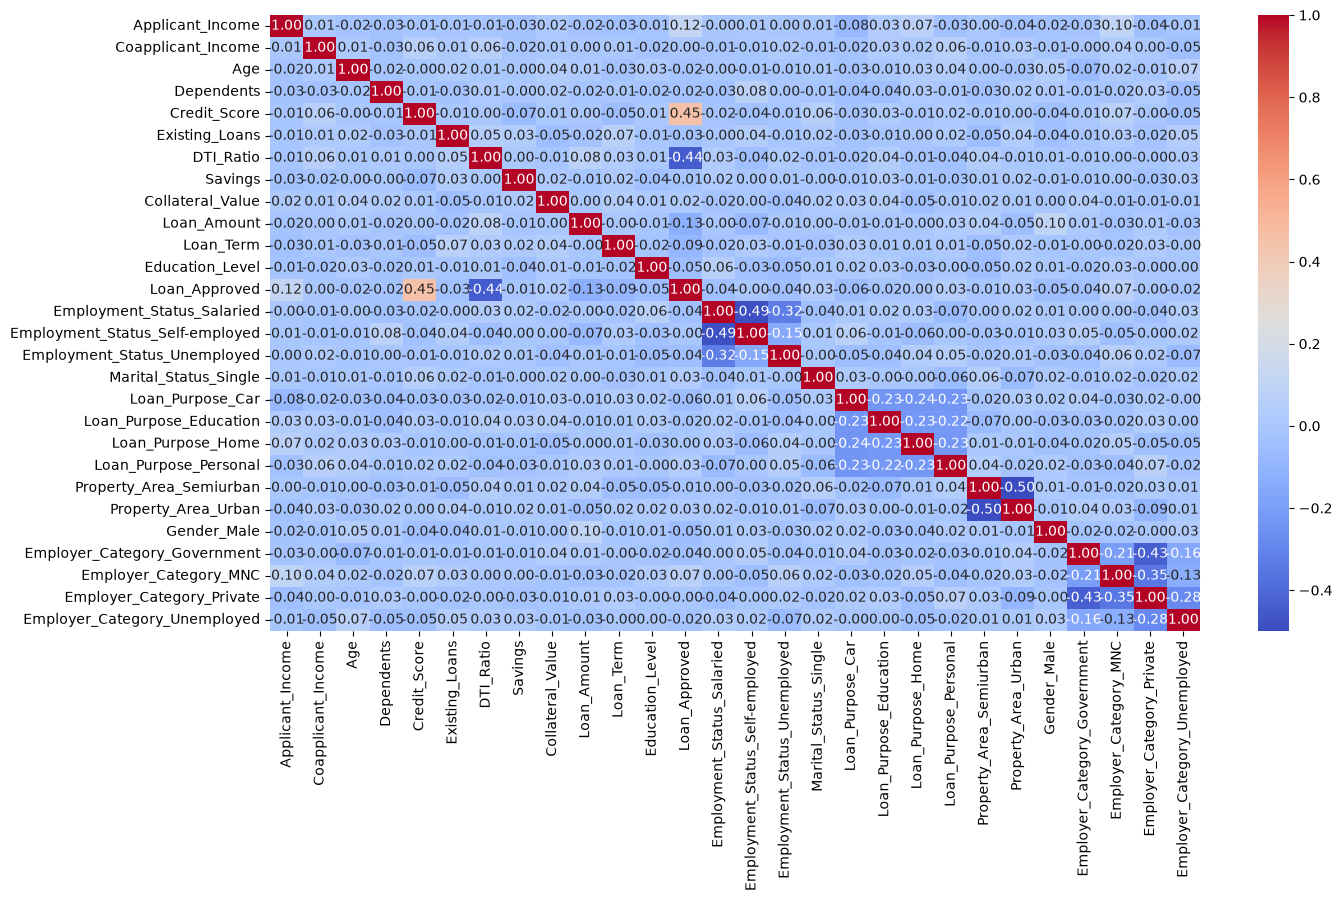

In [58]:
nums_cols = df.select_dtypes(include='number')
corr_matrix = nums_cols.corr()

plt.figure(figsize=(15, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

In [59]:
nums_cols.corr()['Loan_Approved'].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

### Train Test Split + Feature Scaling

In [60]:
X = df.drop("Loan_Approved", axis=1)
y = df["Loan_Approved"]

In [61]:
X.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


In [62]:
# Performing Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [63]:
X_test.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
521,13023.0,6675.0,53.000000,3.0,628.0,3.0,0.347263,10051.000000,26309.0,22947.000000,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
737,15917.0,6787.0,42.000000,0.0,588.0,4.0,0.410000,922.000000,13476.0,20522.825263,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
740,7560.0,3530.0,52.000000,3.0,606.0,0.0,0.580000,9940.452632,21795.0,5876.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
660,19022.0,574.0,59.000000,0.0,725.0,4.0,0.410000,1463.000000,44498.0,8433.000000,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
411,4967.0,5797.0,39.971579,3.0,697.0,4.0,0.580000,1095.000000,3017.0,33926.000000,...,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0


In [65]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Train and Evaluate Models

In [74]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, accuracy_score, precision_score, f1_score, confusion_matrix

log_model = LogisticRegression()
log_model.fit(X_train_scaled, y_train)

y_pred = log_model.predict(X_test_scaled)

# Evaluation
print("Logistic Regression Model")
print("Precision:" , precision_score(y_test, y_pred)*100, "%")
print("Recall:", recall_score(y_test, y_pred)*100, "%")
print("F1 Score:", f1_score(y_test, y_pred)*100, "%")
print("Accuracy:", accuracy_score(y_test, y_pred)*100, "%")
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Logistic Regression Model
Precision: 78.33333333333333 %
Recall: 77.04918032786885 %
F1 Score: 77.68595041322314 %
Accuracy: 86.5 %
Confusion Matrix: 
 [[126  13]
 [ 14  47]]


In [80]:
# KNN 
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=7)
knn_model.fit(X_train_scaled, y_train)

y_pred = knn_model.predict(X_test_scaled)

# Evaluation
print("K-Nearest Neighbor (KNN) Model")
print("Precision:" , precision_score(y_test, y_pred)*100, "%")
print("Recall:", recall_score(y_test, y_pred)*100, "%")
print("F1 Score:", f1_score(y_test, y_pred)*100, "%")
print("Accuracy:", accuracy_score(y_test, y_pred)*100, "%")
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

K-Nearest Neighbor (KNN) Model
Precision: 60.86956521739131 %
Recall: 45.90163934426229 %
F1 Score: 52.336448598130836 %
Accuracy: 74.5 %
Confusion Matrix: 
 [[121  18]
 [ 33  28]]


In [84]:
from sklearn.naive_bayes import GaussianNB

gnb_model = GaussianNB()
gnb_model.fit(X_train_scaled, y_train)

y_pred = gnb_model.predict(X_test_scaled)

# Evaluation
print("Naive Bayes Model")
print("Precision:" , precision_score(y_test, y_pred)*100, "%")
print("Recall:", recall_score(y_test, y_pred)*100, "%")
print("F1 Score:", f1_score(y_test, y_pred)*100, "%")
print("Accuracy:", accuracy_score(y_test, y_pred)*100, "%")
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Naive Bayes Model
Precision: 80.35714285714286 %
Recall: 73.77049180327869 %
F1 Score: 76.92307692307693 %
Accuracy: 86.5 %
Confusion Matrix: 
 [[128  11]
 [ 16  45]]


## Best Model on the basis of Precision - Naive Bayes

# Feature Engineering

In [89]:
df['DTI_Ratio_sq'] = df['DTI_Ratio'] ** 2
df['Credit_Score_sq'] = df['Credit_Score'] ** 2 

X = df.drop(columns=['Loan_Approved', 'Credit_Score', 'DTI_Ratio'])
y = df['Loan_Approved']

# Performing Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [90]:
log_model = LogisticRegression()
log_model.fit(X_train_scaled, y_train)

y_pred = log_model.predict(X_test_scaled)

# Evaluation
print("Logistic Regression Model")
print("Precision:" , precision_score(y_test, y_pred)*100, "%")
print("Recall:", recall_score(y_test, y_pred)*100, "%")
print("F1 Score:", f1_score(y_test, y_pred)*100, "%")
print("Accuracy:", accuracy_score(y_test, y_pred)*100, "%")
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Logistic Regression Model
Precision: 79.03225806451613 %
Recall: 80.32786885245902 %
F1 Score: 79.67479674796748 %
Accuracy: 87.5 %
Confusion Matrix: 
 [[126  13]
 [ 12  49]]


In [91]:
knn_model = KNeighborsClassifier(n_neighbors=7)
knn_model.fit(X_train_scaled, y_train)

y_pred = knn_model.predict(X_test_scaled)

# Evaluation
print("K-Nearest Neighbor (KNN) Model")
print("Precision:" , precision_score(y_test, y_pred)*100, "%")
print("Recall:", recall_score(y_test, y_pred)*100, "%")
print("F1 Score:", f1_score(y_test, y_pred)*100, "%")
print("Accuracy:", accuracy_score(y_test, y_pred)*100, "%")
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

K-Nearest Neighbor (KNN) Model
Precision: 63.04347826086957 %
Recall: 47.540983606557376 %
F1 Score: 54.20560747663551 %
Accuracy: 75.5 %
Confusion Matrix: 
 [[122  17]
 [ 32  29]]


In [92]:
gnb_model = GaussianNB()
gnb_model.fit(X_train_scaled, y_train)

y_pred = gnb_model.predict(X_test_scaled)

# Evaluation
print("Naive Bayes Model")
print("Precision:" , precision_score(y_test, y_pred)*100, "%")
print("Recall:", recall_score(y_test, y_pred)*100, "%")
print("F1 Score:", f1_score(y_test, y_pred)*100, "%")
print("Accuracy:", accuracy_score(y_test, y_pred)*100, "%")
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Naive Bayes Model
Precision: 78.33333333333333 %
Recall: 77.04918032786885 %
F1 Score: 77.68595041322314 %
Accuracy: 86.5 %
Confusion Matrix: 
 [[126  13]
 [ 14  47]]
